<center> 
    <a href="https://www.visual-layer.com" target="_blank" rel="noopener noreferrer">
    <picture>
    <source media="(prefers-color-scheme: dark)" srcset="https://raw.githubusercontent.com/visual-layer/visuallayer/main/imgs/vl_horizontal_logo_dark_mode.png" width=200>
    <source media="(prefers-color-scheme: light)" srcset="https://raw.githubusercontent.com/visual-layer/visuallayer/main/imgs/vl_horizontal_logo.png" width=200>
    <img alt="vl logo." src="https://raw.githubusercontent.com/visual-layer/fastdup/main/gallery/visual_layer_logo.png" width=400>
    </picture>
    </a><br>
    <a href="https://github.com/visual-layer/fastdup" target="_blank" style="text-decoration: none;"> GitHub </a> •
    <a href="https://discord.com/invite/Dqw458EG/" target="_blank" style="text-decoration: none;"> Join Discord Community </a> •
    <a href="https://visual-layer.readme.io/discuss" target="_blank" style="text-decoration: none;"> Discussion Forum </a>
</center>

<center> 
    <a href="https://medium.com/visual-layer" target="_blank" style="text-decoration: none;"> Blog </a> •
    <a href="https://visual-layer.readme.io/" target="_blank" style="text-decoration: none;"> Documentation </a> •
    <a href="https://visual-layer.com/about" target="_blank" style="text-decoration: none;"> About Us </a> 
</center>


<br>

<center> 
<div style="text-align: center; margin-top:50px;">
    <a href="https://visual-layer.com/" style="padding:10px;">
                <img alt="site" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/web.png" width="50"></a>
    <a href="https://medium.com/visual-layer" style="padding:10px;">
                <img alt="blog" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/forum.png" width="50"></a>
    <a href="https://github.com/visual-layer/fastdup" style="padding:10px;">
                <img alt="github" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/github.png" width="50"></a>
    <a href="https://discord.com/invite/Dqw458EG/" style="padding:10px;">
                <img alt="slack" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/discord.png" width="50"></a>
    <a href="https://www.linkedin.com/company/visual-layer/" style="padding:10px;">
                <img alt="linkedin" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/linkedin.png" width="50"></a>
    <a href="https://www.youtube.com/@visual-layer" style="padding:10px;">
                <img alt="youtube" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/youtube.png" width="50"></a>
    <a href="https://twitter.com/visual_layer" style="padding:10px;">
                <img alt="twitter" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/x.png" width="50"></a>
</div>
</center>

# Compute Embeddings Using DINOv2 Or Any ONNX Model 


[![Open in Colab](https://img.shields.io/badge/Open%20in%20Colab-blue?style=for-the-badge&logo=google-colab&labelColor=gray)](https://colab.research.google.com/github/visual-layer/fastdup/blob/main/examples/embeddings-onnx-dinov2.ipynb)
[![Open in Kaggle](https://img.shields.io/badge/Open%20in%20Kaggle-blue?style=for-the-badge&logo=kaggle&labelColor=gray)](https://kaggle.com/kernels/welcome?src=https://github.com/visual-layer/fastdup/blob/main/examples/embeddings-onnx-dinov2.ipynb)
[![Explore the Docs](https://img.shields.io/badge/Explore%20the%20Docs-blue?style=for-the-badge&labelColor=gray&logo=read-the-docs)](https://visual-layer.readme.io/docs/embeddings-onnx-dinov2)

This notebook shows how to extract feature vectors efficiently using [DINOv2](https://github.com/facebookresearch/dinov2) by Meta AI Research or any ONNX model and visualize the embeddings using TSNE.

## Installation

We will be using a free tool [fastdup](https://github.com/visual-layer/fastdup) to efficiently extract the embeddings on CPU.

In [ ]:
import sys
if "google.colab" in sys.modules:
    # Running in Google Colab
    !pip install --force-reinstall --no-cache-dir numpy==1.26.4 scipy fastdup plotly scikit-learn
else:
    # Running outside Colab
    !pip install -Uq fastdup plotly scikit-learn


## Download Oxford Pets Dataset

For demonstration, we will use a widely available and well curated dataset - [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/).

Feel free to swap this dataset with your own.

In [ ]:
!wget https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz -O images.tar.gz
!tar xf images.tar.gz

## Import and Run

Now we need to import fastdup and run extract the embedding of the dataset.

In [1]:
import fastdup
fastdup.__version__

/home/dnth/anaconda3/envs/fastdup2021/lib/python3.10/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (2.2.1) or chardet (5.2.0)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(


'2.0.21'

Now specify the `input_dir` and `work_dir` for the run.

- `input_dir` - A folder that stores your image dataset.

- `work_dir` - A folder to save all artifacts from the run. Optional.

In [2]:
fd = fastdup.create(input_dir="images/")


fastdup By Visual Layer, Inc. 2024. All rights reserved.

A fastdup dataset object was created!

Input directory is set to "images"
Work directory is set to "work_dir"

The next steps are:
   1. Analyze your dataset with the .run() function of the dataset object
   2. Interactively explore your data on your local machine with the .explore() function of the dataset object

For more information, use help(fastdup) or check our documentation https://docs.visual-layer.com/docs/getting-started-with-fastdup.



We are ready to run now.

> **Note** - Runtime on a 2-core Google Colab node may be slow, we recommend running on 32-core machine to get x16 speedup. 

Arguments - 

- `model_path` - The model to use for the run. Choose `dinov2s` or `dinov2b`.
- `cc_threshold` - Connected component threshold. Read more [here](https://visual-layer.readme.io/docs/dataset-cleanup) to set an approriate value for your dataset.

You can optionally use your own ONNX model for the extraction. 

```python
fd.run(model_path='your-model.onnx', cc_threshold=0.8, d=384)
```

If you use your own ONNX model you need to specify the value of `d`, the output dimension of the model.

> **NOTE**: For `dinov2s`, `d` is `384` and for `dinov2b`, `d` is `786`

In [ ]:
fd.run(model_path='dinov2s', cc_threshold=0.8, overwrite=True)

## Image Clusters

Let's debug the embedding quality by clustering group of similar images and visualizing them.

In the visualization below, `component` refers to the cluster number. For example -

- `component` `933` refers to cluster `933` found in the dataset.

- `num_images` refers to the number of images in the cluster (`component`).

- `mean_distance` refers to the mean distance of all the images in the cluster (`component`).

Generating gallery:   0%|          | 0/20 [00:00<?, ?it/s]

Finished OK. Components are stored as image files work_dir/galleries/components_[index].jpg
Stored components visual view in  work_dir/galleries/components.html
Execution time in seconds 3.3
########################################################################################
Would you like to see awesome visualizations for some of the most popular academic datasets?
Click here to see and learn more: https://app.visual-layer.com/vl-datasets?utm_source=fastdup
########################################################################################



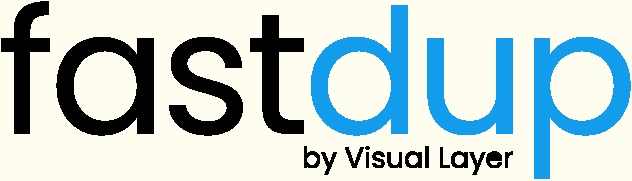
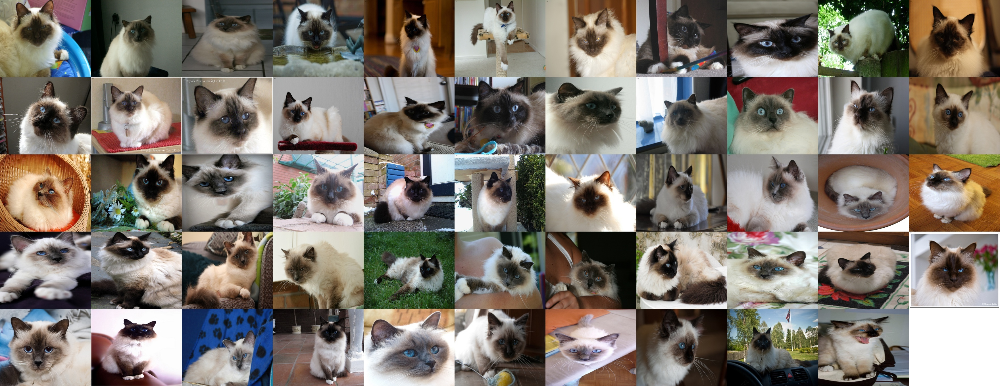
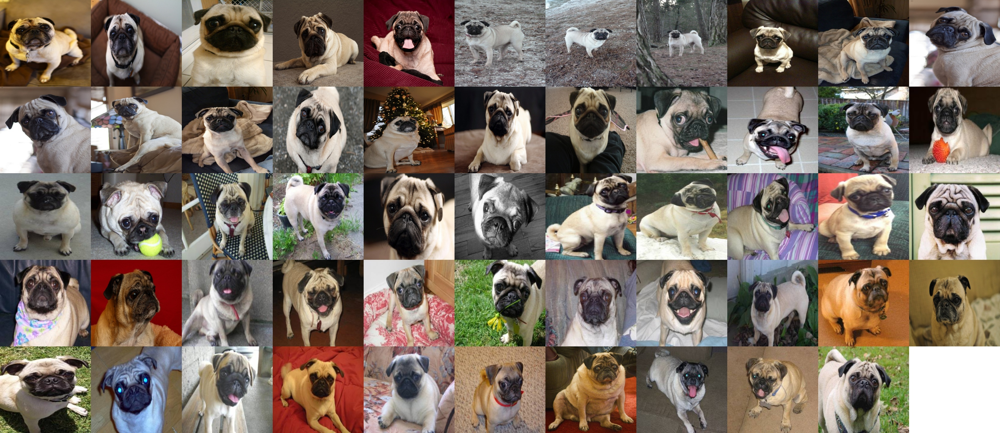
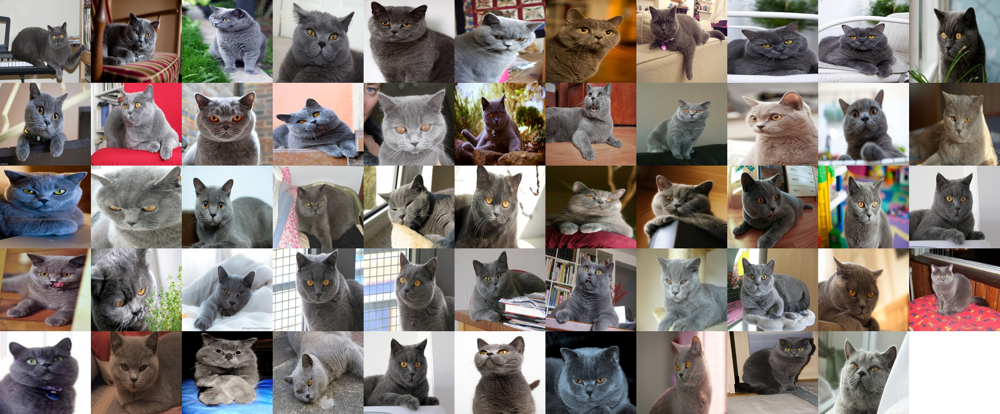
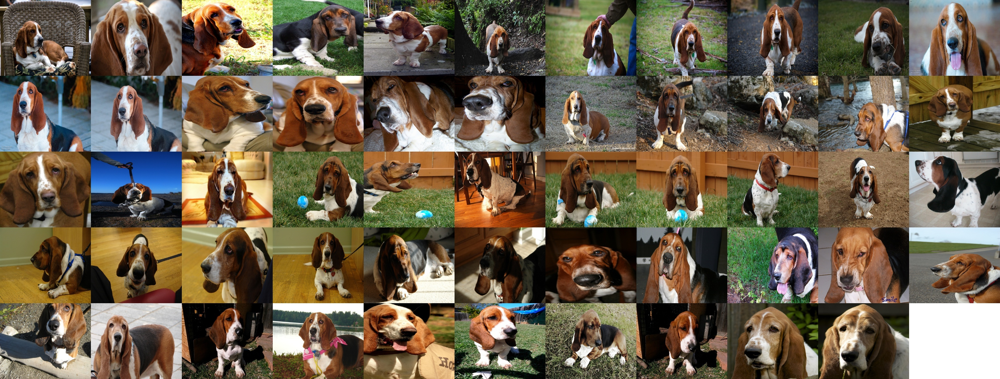
...
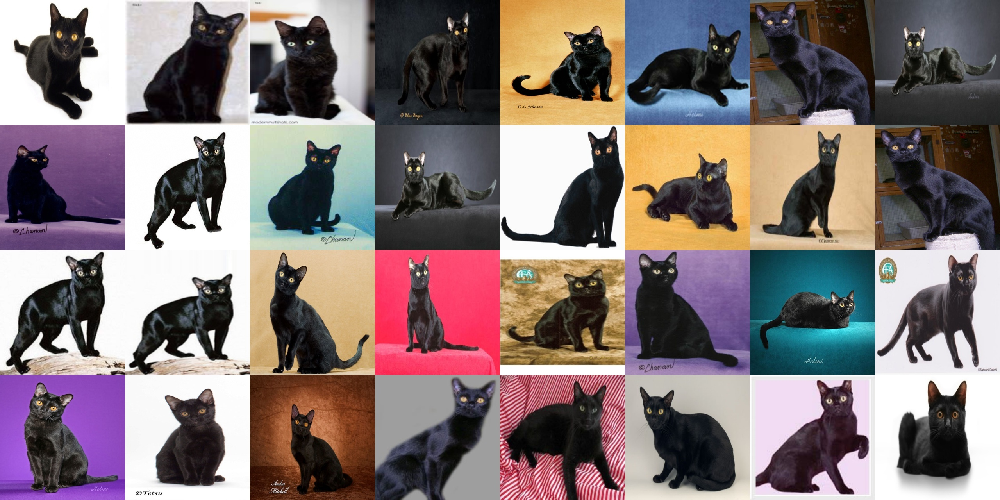
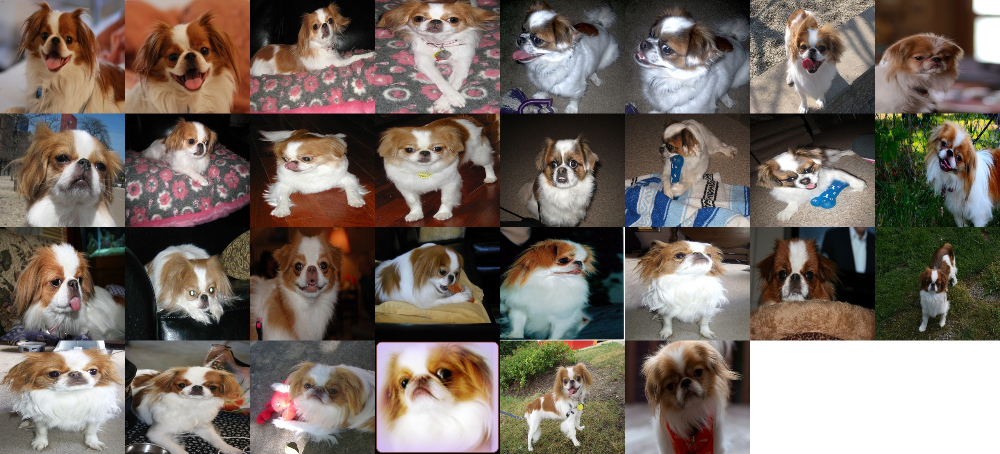
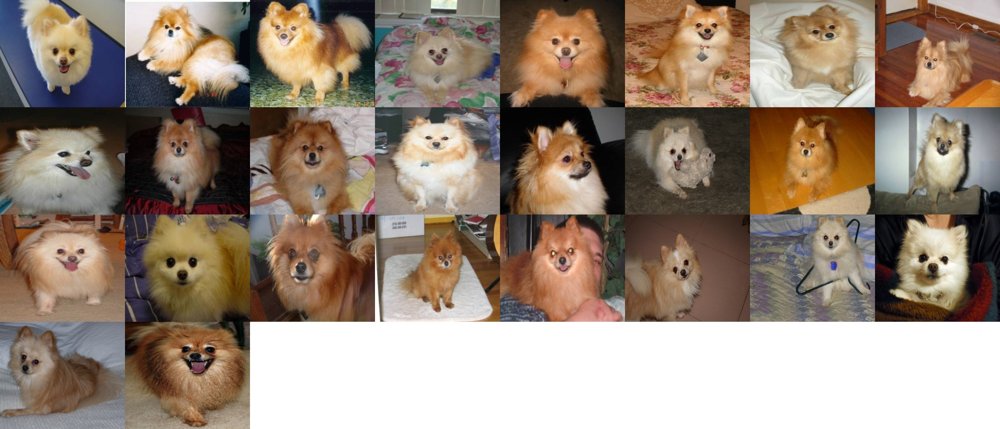
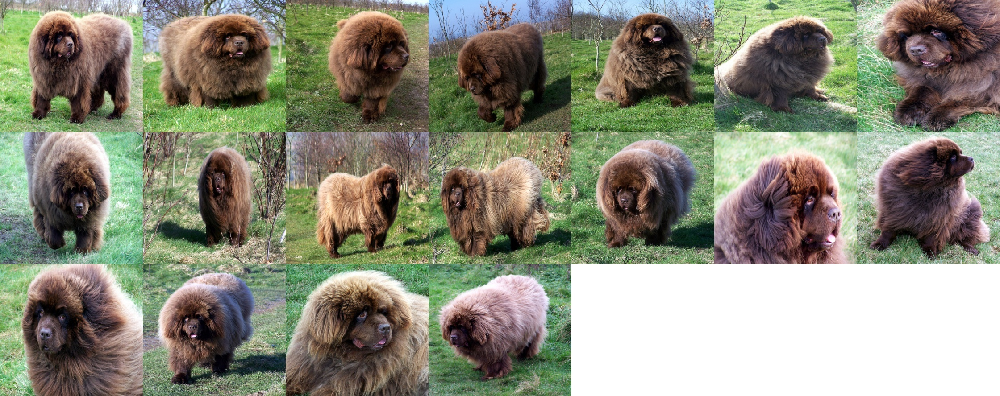
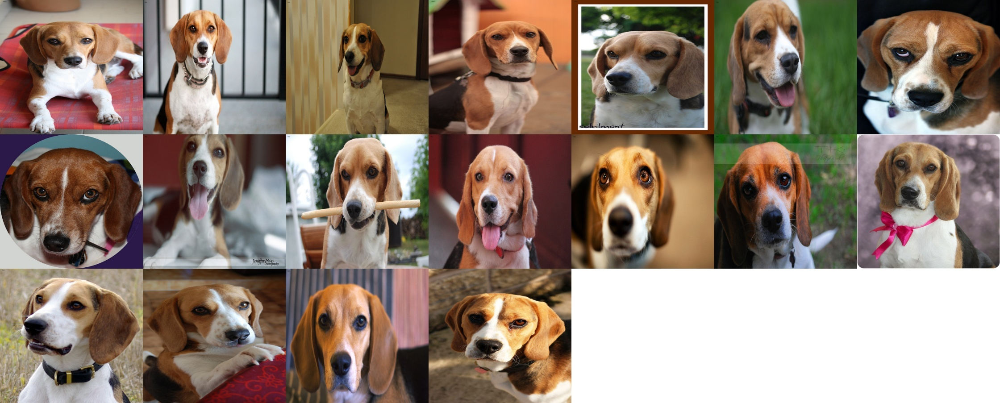

0

In [5]:
fd.vis.component_gallery()

## Embeddings
By fastdup on the image dataset, the embeddings are saves in a file called `atrain_features.dat` in your `work_dir`.

Let's load the embeddings and filenames.

> **NOTE**: Since we are using `dinov2s` model, the value of `d` is 384. Adjust accordingly.

In [6]:
filenames, feature_vec = fastdup.load_binary_feature("work_dir/atrain_features.dat", d=384)  

In [7]:
print("Embedding dimensions", feature_vec.shape)

Embedding dimensions (7384, 384)


There you go! The embeddings of the dataset! 

You can save this to be used for other purposes. But, if you're curious let's visualize the embeddings using TSNE.

## Visualize with TSNE
t-SNE (t-distributed stochastic neighbor embedding) is a machine learning algorithm used for data visualization. It is a nonlinear dimensionality reduction technique that maps high-dimensional data into a low-dimensional space (typically two or three dimensions) for visualization purposes.

Before we start with the visualization let's get the neccessary components to visualize.

First, let's get the cluster component (cluster) ID. 

As a result of the run, each image now is associated with a `component_id`.
Let's view them.

In [8]:
import os
import pandas as pd

connected_components_df = pd.read_csv(os.path.join('work_dir', 'connected_components.csv'))

Each row in the connected components `DataFrame` represents one image in your dataset. In this case, we have 7384 rows in the DataFrame which corresponds to the number of images in the Oxford-IIIT Pet dataset.

The `__id` column refers to the image ID in fastdup and `component_id` refers to the component (or cluster) ID to which the image is associated with.

In [9]:
connected_components_df

,__id,component_id,count,mean_distance,min_distance,max_distance
0,0,0,0,0.000000,0.000000,0.000000
1,1,1,0,0.000000,0.000000,0.000000
2,2,2,18,0.889725,0.809101,0.943508
3,3,3,0,0.000000,0.000000,0.000000
4,4,4,0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...
7379,7385,4763,8,0.815082,0.813455,0.816710
7380,7386,4928,0,0.000000,0.000000,0.000000
7381,7387,4929,0,0.000000,0.000000,0.000000
7382,7388,4930,0,0.000000,0.000000,0.000000


Let's get the `component_id` for each filename as a numpy array.

In [10]:
connected_components_df
component_id = connected_components_df['component_id'].to_numpy()

Let's use TSNE to visualize the embeddings.

In [11]:
import numpy as np
import plotly.express as px
from sklearn.manifold import TSNE
import pandas as pd

import numpy as np
import plotly.express as px
from sklearn.manifold import TSNE
import pandas as pd

X = feature_vec
y = component_id

# Instantiate and fit TSNE model
tsne = TSNE(n_components=3, verbose=1, perplexity=40, n_iter=300)
tsne_result = tsne.fit_transform(X)

# Create a pandas dataframe with the embeddings and labels
df = pd.DataFrame({'tsne_1': tsne_result[:,0], 
                   'tsne_2': tsne_result[:,1], 
                   'tsne_3': tsne_result[:,2], 
                   'component': y, 
                   'filename': filenames})

# Create a Plotly 3D scatter plot with colored points
fig = px.scatter_3d(df, x='tsne_1', y='tsne_2', z='tsne_3', 
                    color='component', 
                    opacity=0.5, 
                    hover_data=['component', 'filename'])
fig.show()

[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 7384 samples in 0.001s...
[t-SNE] Computed neighbors for 7384 samples in 0.450s...
[t-SNE] Computed conditional probabilities for sample 1000 / 7384
[t-SNE] Computed conditional probabilities for sample 2000 / 7384
[t-SNE] Computed conditional probabilities for sample 3000 / 7384
[t-SNE] Computed conditional probabilities for sample 4000 / 7384
[t-SNE] Computed conditional probabilities for sample 5000 / 7384
[t-SNE] Computed conditional probabilities for sample 6000 / 7384
[t-SNE] Computed conditional probabilities for sample 7000 / 7384
[t-SNE] Computed conditional probabilities for sample 7384 / 7384
[t-SNE] Mean sigma: 13.449090
[t-SNE] KL divergence after 250 iterations with early exaggeration: 63.257359
[t-SNE] KL divergence after 300 iterations: 1.803941


If everything goes well you should see something like this.
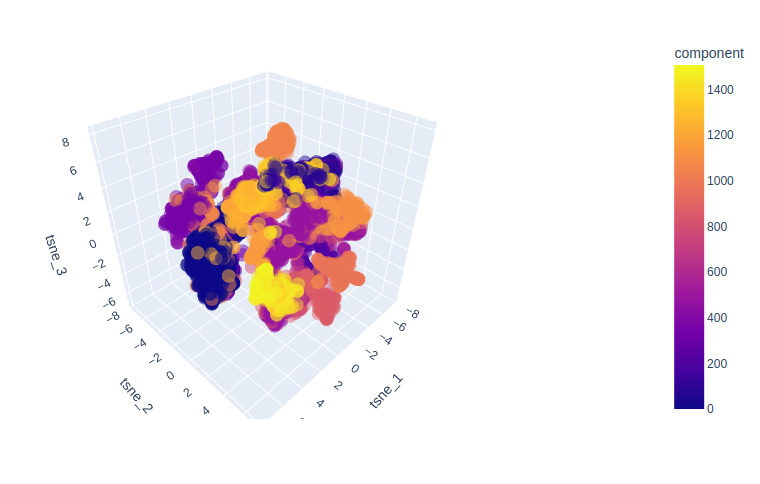

## Wrap up

With the embeddings extracted, we'll leave it to you on how you'd use them. Find anomalies, duplicates, or visualize them, whatever comes to mind.

Feel free to check out our notebooks on how to use fastdup to find issues in your visual datasets. In combination with DINOv2 models, this could significantly improve the quality of your image dataset!

Next, feel free to check out other tutorials -

+ ⚡ [**Quickstart**](https://nbviewer.org/github/visual-layer/fastdup/blob/main/examples/quick-dataset-analysis.ipynb): Learn how to install fastdup, load a dataset and analyze it for potential issues such as duplicates/near-duplicates, broken images, outliers, dark/bright/blurry images, and view visually similar image clusters. If you're new, start here!
+ 🧹 [**Clean Image Folder**](https://nbviewer.org/github/visual-layer/fastdup/blob/main/examples/cleaning-image-dataset.ipynb): Learn how to analyze and clean a folder of images from potential issues and export a list of problematic files for further action. If you have an unorganized folder of images, this is a good place to start.
+ 🖼 [**Analyze Image Classification Dataset**](https://nbviewer.org/github/visual-layer/fastdup/blob/main/examples/analyzing-image-classification-dataset.ipynb): Learn how to load a labeled image classification dataset and analyze for potential issues. If you have labeled ImageNet-style folder structure, have a go!
+ 🎁 [**Analyze Object Detection Dataset**](https://nbviewer.org/github/visual-layer/fastdup/blob/main/examples/analyzing-object-detection-dataset.ipynb): Learn how to load bounding box annotations for object detection and analyze for potential issues. If you have a COCO-style labeled object detection dataset, give this example a try. 

<center> 
<div style="text-align: center; margin-top:50px;">
    <a href="https://visual-layer.com/" style="padding:10px;">
                <img alt="site" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/web.png" width="50"></a>
    <a href="https://medium.com/visual-layer" style="padding:10px;">
                <img alt="blog" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/forum.png" width="50"></a>
    <a href="https://github.com/visual-layer/fastdup" style="padding:10px;">
                <img alt="github" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/github.png" width="50"></a>
    <a href="https://discord.com/invite/Dqw458EG/" style="padding:10px;">
                <img alt="slack" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/discord.png" width="50"></a>
    <a href="https://www.linkedin.com/company/visual-layer/" style="padding:10px;">
                <img alt="linkedin" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/linkedin.png" width="50"></a>
    <a href="https://www.youtube.com/@visual-layer" style="padding:10px;">
                <img alt="youtube" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/youtube.png" width="50"></a>
    <a href="https://twitter.com/visual_layer" style="padding:10px;">
                <img alt="twitter" src="https://vl-blog.s3.us-east-2.amazonaws.com/imgs/x.png" width="50"></a>
</div>
<br>
<div style="text-align:center; font-family:'DM Sans',sans-serif; font-style:italic; font-size:12px; max-width:600px; margin: 20px auto auto;">
    <img style="width:200px" alt="logo" src="https://d2iycffepdu1yp.cloudfront.net/design-assets/VL_horizontal_logo.png" width=300>
    <div style="margin-top:20px;">Copyright © 2024 Visual Layer. All rights reserved.</div>
</div>

</center> 